In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from src.run.analysis.hmm_gaf_analyzer import HMMGAFAnalyzer
from src.run.preprocess.config import _project_path

In [36]:
# Percorsi
DATA_ROOT = _project_path("PaHaW/PaHaW/PaHaW_public")
METADATA_PATH = _project_path("PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx")

# Esperimento
TASKS = [8]
FEATURE_NAMES = []
ENGINEERED_FEATURES = ["velocity", "speed"]

# Sweep stati
STATE_GRID = [2, 3, 4]

# Parametri HMM/GAF
COMMON_CFG = dict(
    data_root=DATA_ROOT,
    metadata_path=METADATA_PATH,
    tasks=TASKS,
    feature_names=FEATURE_NAMES,
    engineered_features=ENGINEERED_FEATURES,
    covariance_type="diag",
    n_iter=100,
    tol=1e-3,
    random_state=42,
    algorithm="viterbi",
    verbose=False,
    gaf_target_len=128,
    max_gaf_per_state=12,
    seed=42,
    n_splits=5,
    label_column="Disease",
    positive_value="PD",
)


In [37]:
all_summaries = []

for n_states in STATE_GRID:
    print(f"\n=== Running HMMGAFAnalyzer with n_states={n_states} ===")

    analyzer = HMMGAFAnalyzer(
        **COMMON_CFG,
        n_states=n_states,
        output_dir=_project_path(
            f"experiments/test_iperparametri/hmm/gaf_state_sweep/task_8/speed_velocity/states_{n_states}"
        ),
    )

    summary = analyzer.run()
    all_summaries.append(summary)

print("\nSweep completato.")


=== Running HMMGAFAnalyzer with n_states=2 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.

=== Running HMMGAFAnalyzer with n_states=3 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.

=== Running HMMGAFAnalyzer with n_states=4 ===
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] M

In [39]:
rows = []

for summary in all_summaries:
    metrics = summary["selection_metrics"]
    quality = summary["segmentation_quality"]
    convergence = summary["convergence"]

    rows.append(
        {
            "n_states": summary["hmm"]["n_states"],

            "mean_occupancy_total_variation":
                metrics["mean_occupancy_total_variation"],

            "std_occupancy_total_variation":
                metrics["std_occupancy_total_variation"],

            "mean_gaf_distance":
                metrics["mean_gaf_distance"],

            "mean_fraction_length_one":
                quality["mean_fraction_length_one"],

            "mean_median_segment_length":
                quality["mean_median_segment_length"],

            "mean_median_segments_per_patient":
                quality["mean_median_segments_per_patient"],

            "mean_segments_per_patient":
                quality["mean_segments_per_patient"],

            "max_segments_per_patient":
                quality["max_segments_per_patient"],

            "all_folds_converged":
                convergence["all_folds_converged"],
        }
    )

results_df = pd.DataFrame(rows)
results_df

,n_states,mean_occupancy_total_variation,std_occupancy_total_variation,mean_gaf_distance,mean_fraction_length_one,mean_median_segment_length,mean_median_segments_per_patient,mean_segments_per_patient,max_segments_per_patient,all_folds_converged
0,2,0.016486,0.032971,NaN,0.001904,2222.6,36.0,37.213333,220,True
1,3,0.014787,0.029574,NaN,0.023425,2221.6,70.0,70.240000,397,True
2,4,0.075383,0.020800,58.389266,0.031109,9.4,205.8,207.280000,395,True


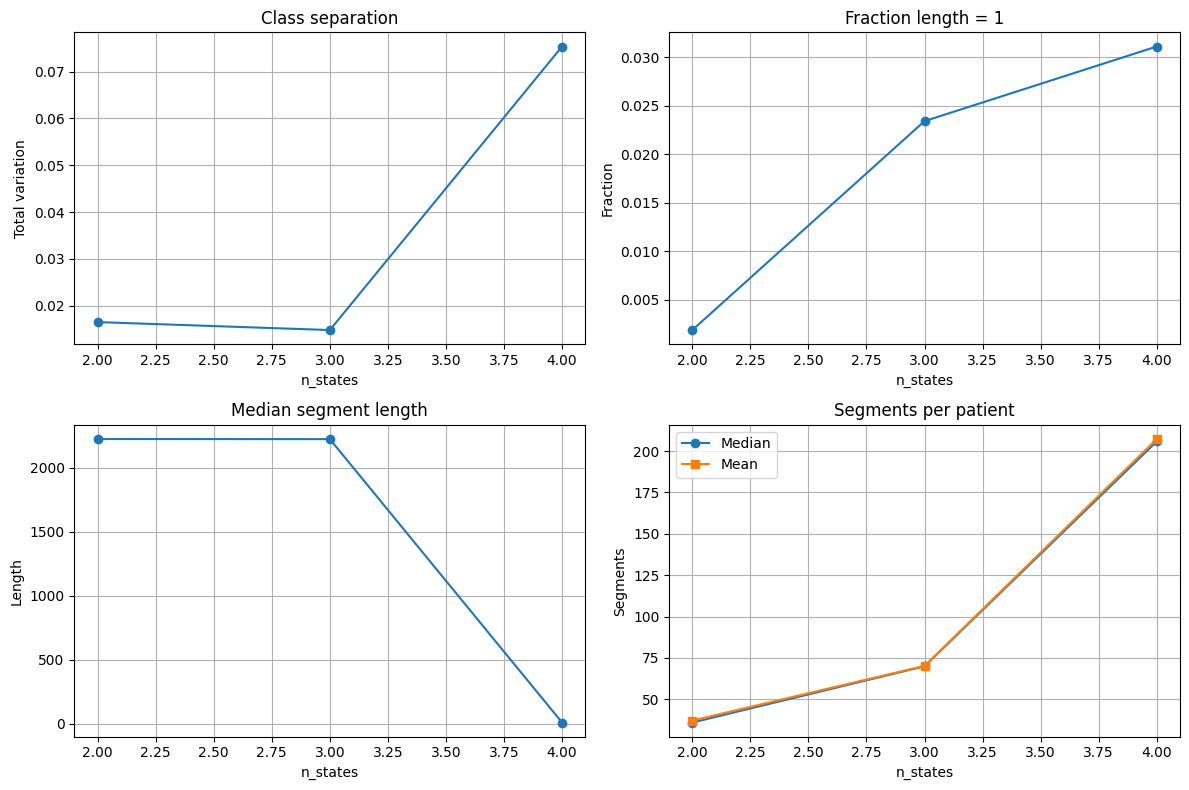

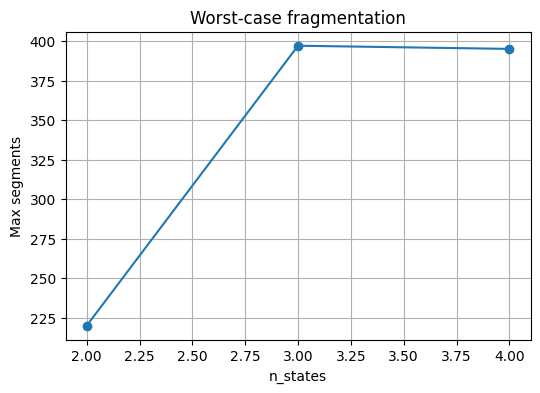

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# ---------------------------------------------------
# Class separation
# ---------------------------------------------------

axes[0, 0].plot(
    results_df["n_states"],
    results_df["mean_occupancy_total_variation"],
    marker="o",
)

axes[0, 0].set_title("Class separation")
axes[0, 0].set_ylabel("Total variation")

# ---------------------------------------------------
# Fraction of segments with length = 1
# ---------------------------------------------------

axes[0, 1].plot(
    results_df["n_states"],
    results_df["mean_fraction_length_one"],
    marker="o",
)

axes[0, 1].set_title("Fraction length = 1")
axes[0, 1].set_ylabel("Fraction")

# ---------------------------------------------------
# Median segment length
# ---------------------------------------------------

axes[1, 0].plot(
    results_df["n_states"],
    results_df["mean_median_segment_length"],
    marker="o",
)

axes[1, 0].set_title("Median segment length")
axes[1, 0].set_ylabel("Length")

# ---------------------------------------------------
# Segments per patient
# ---------------------------------------------------

axes[1, 1].plot(
    results_df["n_states"],
    results_df["mean_median_segments_per_patient"],
    marker="o",
    label="Median",
)

axes[1, 1].plot(
    results_df["n_states"],
    results_df["mean_segments_per_patient"],
    marker="s",
    label="Mean",
)

axes[1, 1].set_title("Segments per patient")
axes[1, 1].set_ylabel("Segments")
axes[1, 1].legend()

# ---------------------------------------------------

for ax in axes.flat:
    ax.grid(True)
    ax.set_xlabel("n_states")

plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))

plt.plot(
    results_df["n_states"],
    results_df["max_segments_per_patient"],
    marker="o",
)

plt.xlabel("n_states")
plt.ylabel("Max segments")
plt.title("Worst-case fragmentation")
plt.grid(True)
plt.show()

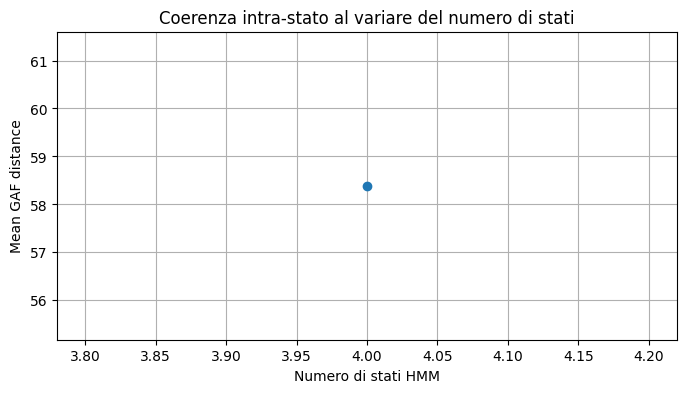

In [41]:
plt.figure(figsize=(8, 4))

plt.plot(results_df["n_states"], results_df["mean_gaf_distance"], marker="o")

plt.xlabel("Numero di stati HMM")
plt.ylabel("Mean GAF distance")
plt.title("Coerenza intra-stato al variare del numero di stati")
plt.grid(True)
plt.show()

In [42]:
display(
    results_df[
        [
            "n_states",
            "mean_occupancy_total_variation",
            "std_occupancy_total_variation",
            "mean_gaf_distance",
        ]
    ].sort_values(
        by=[
            "mean_occupancy_total_variation",
            "mean_gaf_distance",
        ],
        ascending=[False, True],
    )
)

,n_states,mean_occupancy_total_variation,std_occupancy_total_variation,mean_gaf_distance
2,4,0.075383,0.020800,58.389266
0,2,0.016486,0.032971,NaN
1,3,0.014787,0.029574,NaN


In [43]:
states = [2, 3, 4]

for n_states in states:
    output_dir = Path(
        f"experiments/test_iperparametri/hmm/gaf_state_sweep/task_8/xy/states_{n_states}"
    )
    output_dir.mkdir(parents=True, exist_ok=True)
    results_df.to_csv(
        output_dir / "state_sweep_summary.csv",
        index=False,
    )

results_df

,n_states,mean_occupancy_total_variation,std_occupancy_total_variation,mean_gaf_distance,mean_fraction_length_one,mean_median_segment_length,mean_median_segments_per_patient,mean_segments_per_patient,max_segments_per_patient,all_folds_converged
0,2,0.016486,0.032971,NaN,0.001904,2222.6,36.0,37.213333,220,True
1,3,0.014787,0.029574,NaN,0.023425,2221.6,70.0,70.240000,397,True
2,4,0.075383,0.020800,58.389266,0.031109,9.4,205.8,207.280000,395,True


In [27]:
print(all_summaries[0]["selection_metrics"].keys())

dict_keys(['metric', 'mean_occupancy_total_variation', 'std_occupancy_total_variation', 'fold_occupancy_total_variation', 'mean_gaf_distance', 'fold_gaf_distance'])


In [44]:
for summary in all_summaries:
    print(
        f"\nStates = {summary['hmm']['n_states']}"
    )

    for fold in summary["folds"]:
        print(
            fold["mean_gaf_distance_by_state"]
        )


States = 2
{0: nan, 1: nan}
{0: 64.42163772583008, 1: 55.4860481262207}
{0: nan, 1: nan}
{0: nan, 1: nan}
{0: nan, 1: nan}

States = 3
{0: nan, 1: nan, 2: nan}
{0: 85.02859675089518, 1: 56.535010528564456, 2: 58.09555180867513}
{0: nan, 1: nan, 2: nan}
{0: nan, 1: nan, 2: nan}
{0: nan, 1: nan, 2: nan}

States = 4
{0: 59.243377685546875, 1: nan, 2: nan, 3: 53.355569712320964}
{0: 58.55415395100911, 1: 85.1026830037435, 2: 56.76314188639323, 3: 59.28842569986979}
{0: 58.4621342976888, 1: nan, 2: nan, 3: 54.88176956176758}
{0: 57.76968943277995, 1: nan, 2: nan, 3: 55.83322448730469}
{0: 59.1646733601888, 1: nan, 2: nan, 3: 55.328017171223955}
